# loop_scope (`loop_scope`)

The knowledge graph around `loop_scope`. This notebook draws the picture (`loop_scope.png`) and writes the explanation of every relation of the concept: read it in [loop_scope.md](loop_scope.md).

In [1]:
# 1. Load the knowledge graph visualizer (cell 1 of notebooks/kg_visualizer.ipynb) and the graph itself.
import json
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'data' / 'raw').exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
_visualizer = json.load(open(ROOT / 'notebooks' / 'kg_visualizer.ipynb', encoding='utf-8'))
exec(''.join(_visualizer['cells'][1]['source']))
print(_loaded)


Loaded C:\Users\magnu\OneDrive\Desktop\ES_VIterbi_Personalized_Learning\data\raw\chapter1_kg_updated.json | version 3.9.8 (3.9.7 + one primary per misconception (S9c) and the … | nodes 1376 | edges 1943


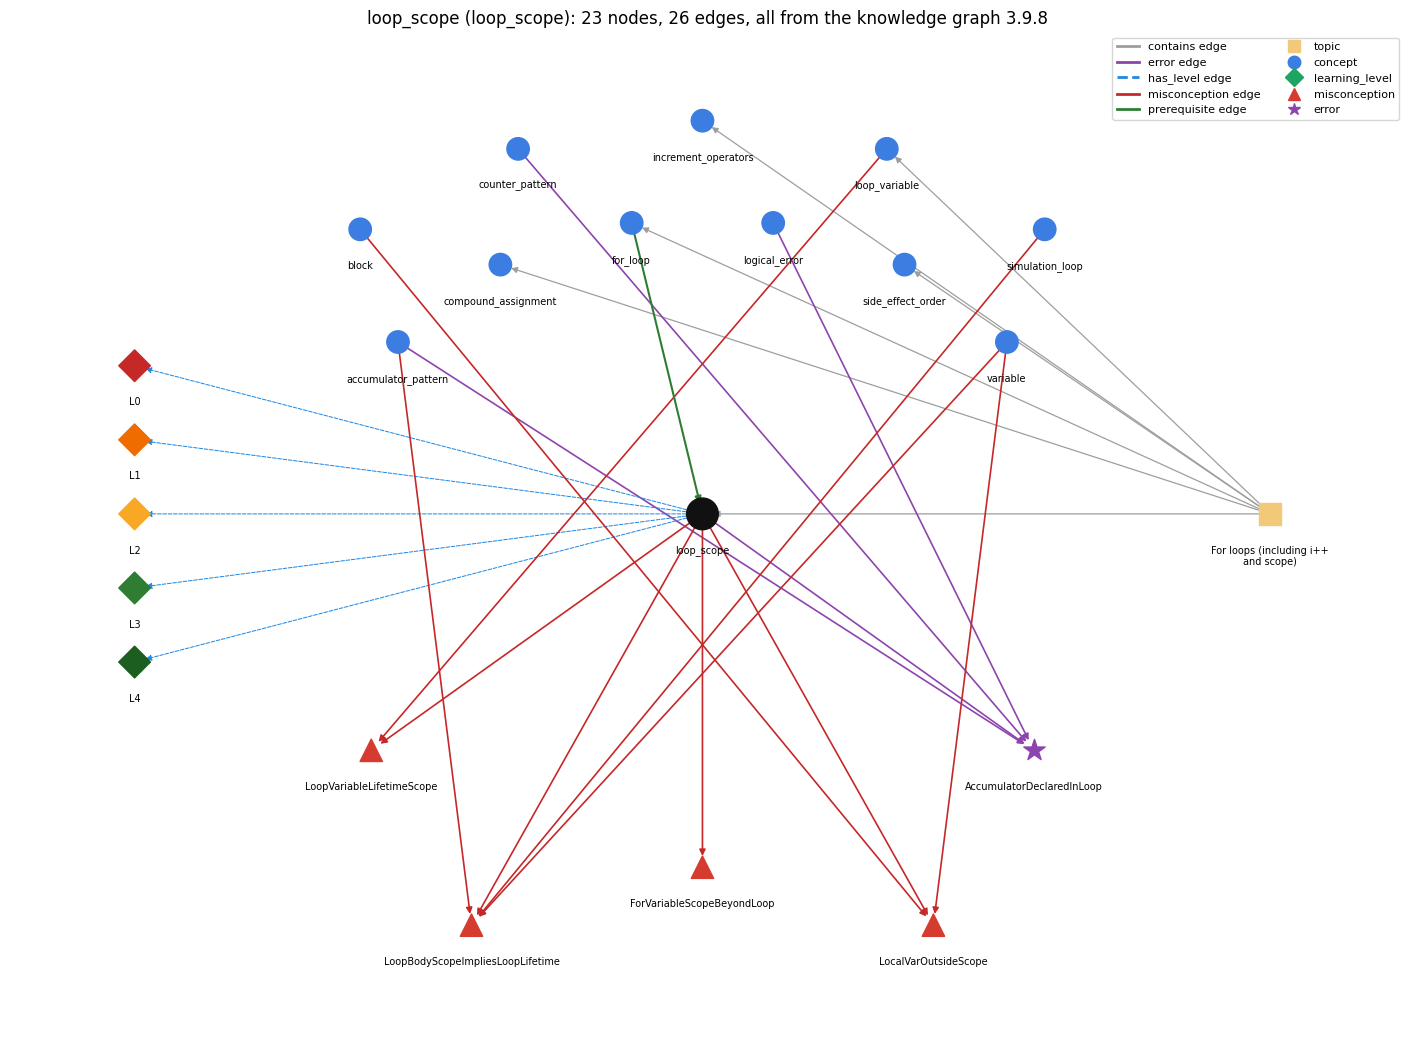

loop_scope: 23 nodes, 26 edges. Written: loop_scope.png, loop_scope.md


In [2]:
CONCEPT = 'loop_scope'

# 2. The view of the concept: the picture, and the explanation of every relation.
import re
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

HERE = Path.cwd()                      # concept_wise_graph/<concept>/
VIEW_LAYERS = {'topic', 'concept', 'learning_level', 'misconception', 'error'}
VIEW_ETYPES = {'contains', 'prerequisite', 'parallel', 'has_level', 'misconception', 'error'}
H, _ = filter_graph(VIEW_LAYERS, VIEW_ETYPES, 'All', '', 1, True, CONCEPT)   # only edges of the knowledge graph

# ---- the picture ----
pos = {n: (x, -y) for n, (x, y) in radial_layout(H, CONCEPT).items()}
S = nx.DiGraph()
S.add_nodes_from(H.nodes())
fig, ax = plt.subplots(figsize=(18, 13))
keys = []
for et in sorted({d['etype'] for _, _, d in H.edges(data=True)}):
    st = EDGE_STYLE[et]
    nx.draw_networkx_edges(S, pos, ax=ax, edgelist=[(u, v) for u, v, d in H.edges(data=True) if d['etype'] == et],
                           edge_color=st['color'], width=st['width'] * 0.6, style='dashed' if st['dashes'] else 'solid',
                           arrows=True, arrowstyle='-' if et == 'parallel' else '-|>', arrowsize=9, node_size=260)
    keys.append(Line2D([], [], color=st['color'], lw=2, ls='--' if st['dashes'] else '-', label=et + ' edge'))
MARK = {'box': 's', 'dot': 'o', 'diamond': 'D', 'triangle': '^', 'star': '*'}
for lay, st in LAYER_STYLE.items():
    ns = [n for n, d in H.nodes(data=True) if d['layer'] == lay]
    if ns:
        cols = ([LEVEL_COLOR.get(H.nodes[n]['label'], st['color']) for n in ns] if lay == 'learning_level'
                else ['#111111' if n == CONCEPT else st['color'] for n in ns])
        nx.draw_networkx_nodes(S, pos, ax=ax, nodelist=ns, node_color=cols, node_shape=MARK[st['shape']],
                               node_size=[520 if n == CONCEPT else 260 for n in ns])
        keys.append(Line2D([], [], color=st['color'], marker=MARK[st['shape']], ls='', ms=9, label=lay))
nx.draw_networkx_labels(S, {n: (x, y - 55) for n, (x, y) in pos.items()}, ax=ax, font_size=7,
                        labels={n: _wrap(d['label'], 24) for n, d in H.nodes(data=True)}, verticalalignment='top')
ax.set_title(f"{_CONCEPT[CONCEPT].get('label', CONCEPT)} ({CONCEPT}): {H.number_of_nodes()} nodes, "
             f"{H.number_of_edges()} edges, all from the knowledge graph {str(DATA.get('version'))[:5]}")
ax.legend(handles=keys, loc='upper right', fontsize=8, ncol=2)
ax.margins(0.08)
ax.axis('off')
fig.savefig(HERE / f'{CONCEPT}.png', dpi=110, bbox_inches='tight')
plt.show()

# ---- the explanation (<concept>.md): plain text, no tables ----
def md(t):
    """Text from the graph, safe to put in markdown."""
    t = str(t or '').replace('&', '&amp;').replace('<', '&lt;').replace('>', '&gt;')
    return re.sub(r'([*_`|])', r'\\\1', t).strip()

def way(w):
    return md(str(w.get('way') or '').replace('_', ' '))

def ids(xs):
    return ', '.join('`' + str(x) + '`' for x in xs)

def about(o):
    """One line saying what another concept is."""
    d = _CONCEPT.get(o, {})
    lab, desc = d.get('label', o), d.get('description', '')
    if lab == o:                       # no separate label: the description says what it is
        return '*' + md(desc or o) + '*'
    return '*' + md(lab) + (': ' + md(desc) if desc and desc != lab else '') + '*'

def relation(e, other, heading):
    out = [f"### {heading}", '', about(other), '',
           md(e.get('logic') or e.get('edge_logic')) or 'No reasoning is stored on this edge.', '']
    if e.get('grounding'):
        out.append(f"- **Grounding:** {md(str(e['grounding']).replace('_', ' '))}")
    for a, b in ((CONCEPT, other), (other, CONCEPT)):
        if (a, b) in _R_RULE:
            out.append(f"- **How `{a}` combines with `{b}`:** {md(_R_RULE[(a, b)])}")
    return out + ['']

d0 = _CONCEPT[CONCEPT]
rel = concept_related(CONCEPT)
shown = set(H.nodes())
siblings = sorted({v for u, v, d in H.edges(data=True) if d['etype'] == 'contains' and v != CONCEPT})
needs = sorted(rel['needs'], key=lambda e: e['source'])
leads = sorted(rel['unlocks'], key=lambda e: e['target'])
par = sorted(rel['parallel'], key=lambda e: str(sorted((e['source'], e['target']))))
par_other = [e['target'] if e['source'] == CONCEPT else e['source'] for e in par]
L0 = rel['levels'].get('L0', {})

out = [f"# {d0.get('label', CONCEPT)} (`{CONCEPT}`)", '',
       md(d0.get('description', '')), '',
       f"Section {md(d0.get('section', ''))} {md(d0.get('section_title', ''))}, "
       f"topic {md(d0.get('topic', ''))} {md(d0.get('topic_title', ''))}.", '',
       f"![The knowledge graph around {CONCEPT}]({CONCEPT}.png)", '',
       '## At a glance', '',
       '- **Needs first:** ' + (ids(e['source'] for e in needs) or 'nothing'),
       '- **Leads to:** ' + (ids(e['target'] for e in leads) or 'nothing'),
       '- **Learned alongside:** ' + (ids(par_other) or 'nothing'),
       '- **Misconceptions:** ' + (ids(sorted(e['target'] for e in rel['mis'])) or 'none'),
       '- **Errors:** ' + (ids(sorted(e['target'] for e in rel['err'])) or 'none'),
       '- **Levels:** ' + (', '.join(L for L in LEVELS if L in rel['levels']) or 'none'), '',
       f"Everything below comes from the knowledge graph {str(DATA.get('version'))[:5]} "
       f"(`data/raw/chapter1_kg_updated.json`): {H.number_of_edges()} edges around this concept, each explained in the "
       "graph's own words.", '']

out += [f"## What it needs first ({len(needs)})", '',
        f"A prerequisite edge means the other concept has to be understood before `{CONCEPT}`.", '']
for e in needs:
    out += relation(e, e['source'], f"`{e['source']}` comes before `{CONCEPT}`")
if not needs:
    out += ['No prerequisite edge leads into this concept.', '']

out += [f"## What it leads to ({len(leads)})", '', f"These concepts need `{CONCEPT}` first.", '']
for e in leads:
    out += relation(e, e['target'], f"`{CONCEPT}` comes before `{e['target']}`")
if not leads:
    out += ['No concept has this one as a prerequisite.', '']

out += [f"## Learned alongside ({len(par)})", '',
        "A parallel edge joins two concepts that sit side by side: neither is needed before the other.", '']
for e, o in zip(par, par_other):
    out += relation(e, o, f"`{CONCEPT}` alongside `{o}`")
if not par:
    out += ['No parallel edge touches this concept.', '']

for title, one, edges, intro in (
        ('Misconceptions', 'misconception', rel['mis'],
         'A misconception edge states the wrong rule a student may hold about this concept, and the right rule.'),
        ('Errors', 'error', rel['err'],
         'An error edge states the rule that gets broken in a program, and the right rule.')):
    out += [f"## {title} ({len(edges)})", '', intro, '']
    for e in sorted(edges, key=lambda e: e['target']):
        m = e['target']
        node = _MISNODE.get(m, {})
        out += [f"### {m}", '']
        if node.get('label') and node['label'] != m:
            out += ['*' + md(node['label']) + '*', '']
        out += ['- **Wrong rule:** ' + (md(e.get('logic')) or 'not stated on the edge'),
                '- **Right rule:** ' + (md(e.get('twin_logic')) or 'not stated on the edge')]
        if e.get('role'):
            out.append('- **Role of this concept:** ' + md(e['role']))
        for w in L0.get('ways', []):
            if m in (w.get('linked_misconception') or []):
                out.append('- **Shows at level L0 as:** ' + way(w) + ': ' + md(w.get('exact_rule')))
        for o in sorted(_MIS_OWNERS.get(m, set()) - {CONCEPT}):
            if o in shown:
                out.append(f"- **Also an edge from `{o}`:** "
                           + (md(_MIS_EDGE.get((o, m), {}).get('logic')) or 'no rule stated'))
        out.append('')
    if not edges:
        out += [f"The graph has no {one} edge from this concept.", '']

out += [f"## Levels L0 to L4 ({len(rel['levels'])} of 5)", '',
        "Each level edge lists the ways a student shows that level, each with its exact rule.", '']
for L in LEVELS:
    ln, e = _LEVEL_NODE.get(f'{CONCEPT}@{L}'), rel['levels'].get(L)
    if not (ln or e):
        out += [f"### {L}", '', 'The graph has no node for this level.', '']
        continue
    out += [f"### {L}: {md((ln or {}).get('name', ''))}", '']
    if ln and ln.get('criterion'):
        out += [md(ln['criterion']), '']
    if ln and ln.get('deciding_question'):
        out += ['*Deciding question: ' + md(ln['deciding_question']) + '*', '']
    if e and e.get('logic'):
        out += [md(e['logic']), '']
    for w in (e or {}).get('ways', []):
        link = w.get('linked_misconception') or []
        out.append('- **' + way(w) + '** (' + md(RULE_TYPE_NAMES.get(w.get('rule_type'), w.get('rule_type')))
                   + ('; shows ' + ids(link) if link else '') + '): ' + md(w.get('exact_rule')))
    out.append('')

out += ['## Same topic', '']
if rel['topics']:
    t = rel['topics'][0]
    out += [f"`{CONCEPT}` belongs to the topic **{md(G.nodes[t]['label'] if t in G else t)}** (`{t}`). "
            + ('The topic also contains: ' + ids(siblings) + '.' if siblings else 'It is the only concept of that topic.'), '']
else:
    out += ['No topic contains this concept.', '']

rules = G.nodes[CONCEPT].get('rules', [])
out += [f"## Rules of the concept ({len(rules)})", '']
out += ['- **' + md(RULE_TYPE_NAMES.get(t, t)) + ':** ' + md(r) for t, r in rules] or ['No rule is stated on the concept.']
out += ['', '## The whole prerequisite chain', '',
        f"- **Everything it builds on ({len(rel['all_needs'])}):** " + (ids(rel['all_needs']) or 'nothing'),
        f"- **Everything that builds on it ({len(rel['all_unlocks'])}):** " + (ids(rel['all_unlocks']) or 'nothing'),
        '']
(HERE / f'{CONCEPT}.md').write_text('\n'.join(out), encoding='utf-8')
print(f"{CONCEPT}: {H.number_of_nodes()} nodes, {H.number_of_edges()} edges. Written: {CONCEPT}.png, {CONCEPT}.md")
